<div dir="rtl" lang="he" align="right">
<h1 dir="rtl" align="right">מחברת <span dir="ltr">1</span> — <span dir="ltr">Kafka</span> עם עשרה אירועים סינתטיים קבועים</h1>
<p dir="rtl" align="right"><strong>ד״ר פאול אברהמי | הנדסת <span dir="ltr">AI</span> | <span dir="ltr">Python 3.13.12</span></strong></p>
<p dir="rtl" align="right">נעקוב אחרי עשרה אירועים מוכרים: ניצור אותם, נקודד אותם ל־<span dir="ltr">JSON</span>, נשלח אותם לשרת <span dir="ltr">Kafka</span>, נקרא אותם בקבוצת צרכנים, נקרא שוב בקבוצה חדשה ונחשב ספירות וחלונות זמן.</p>
<p dir="rtl" align="right"><strong>מקור הנתונים קבוע:</strong> עשרה אירועים מומצאים בלבד. בכל הרצה נוצרים אותם מזהים ואותם זמנים; אין כאן קריאה מהאינטרנט. ברירת המחדל מעבירה אותם דרך <span dir="ltr">Kafka</span> אמיתי במחשב המקומי.</p>
<p dir="rtl" align="right">המחברת השנייה עוסקת בקליטה רציפה ממקור חי ובכתיבה למנוע חיפוש. כאן מתמקדים ביסודות, ולכן כל תוצאה מספרית ניתנת לחישוב מראש.</p>
</div>

<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">לפני שמתחילים — סביבת הפרויקט</h2>
<ol dir="rtl" align="right"><li dir="rtl" align="right">פתחו ב־<span dir="ltr">Cursor</span> את תיקיית הפרויקט כולה, שבה נמצאים <code dir="ltr">pyproject.toml</code>, התיקייה <code dir="ltr">scripts</code> ושתי המחברות.</li>
<li dir="rtl" align="right">במסוף של אותה תיקייה הכינו את סביבת <span dir="ltr">Python</span>:</li></ol><pre dir="ltr" align="left"><code dir="ltr">uv python install 3.13.12
uv sync --locked</code></pre>
<p dir="rtl" align="right">בחרו במחברת <code dir="ltr">Select Kernel → Python Environments → .venv</code>. ב־<span dir="ltr">Windows</span> זהו הקובץ <code dir="ltr">.venv\Scripts\python.exe</code>.</p>
<p dir="rtl" align="right">למסלול <span dir="ltr">Kafka</span> פתחו <span dir="ltr">Docker Desktop</span> והפעילו את המעבדה:</p><pre dir="ltr" align="left"><code dir="ltr">uv run --locked python scripts/kafka_docker.py start
uv run --locked python scripts/check_kafka.py</code></pre>
<p dir="rtl" align="right">לאחר שהשרת מוכן בחרו <code dir="ltr">Restart Kernel and Run All</code>. הרצה מלאה חדשה בוחרת <span dir="ltr">Topic</span> חדש כדי שלא לערבב תוצאות בין ניסויים.</p>
<p dir="rtl" align="right"><strong>לתרגול ללא שרת:</strong> שנו במפורש <code dir="ltr">USE_KAFKA = False</code> בתא הבא. במסלול הזה ההודעות נשארות בזיכרון <span dir="ltr">Python</span>, והפלט מסומן כ־<span dir="ltr">OFFLINE</span>. שגיאת חיבור במסלול החי אינה גורמת למעבר אוטומטי למצב מקומי.</p>
</div>

<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">מפת הניסוי</h2>
<p dir="rtl" align="right">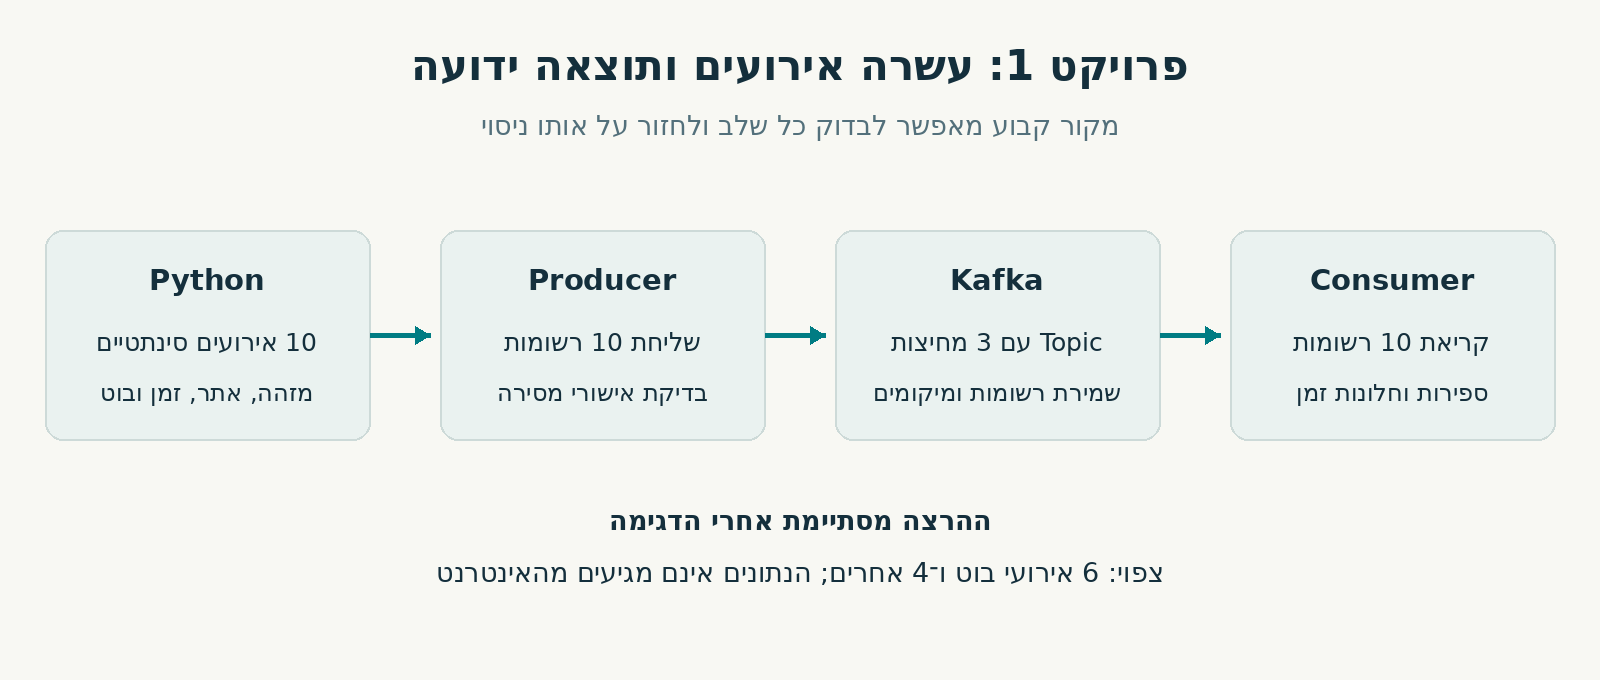</p>
<p dir="rtl" align="right">הנתון העסקי נשאר אותו אירוע לאורך המסלול. ה־<span dir="ltr">Producer</span> וה־<span dir="ltr">Consumer</span> פועלים בקוד <span dir="ltr">Python</span>; שרת <span dir="ltr">Kafka</span> פועל במכולה נפרדת.</p>
</div>

<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">1</span> — הגדרות ומזהה לניסוי</h2>
<p dir="rtl" align="right"><code dir="ltr">USE_KAFKA</code> בוחר אם מתבצעת תקשורת אמיתית עם השרת. <code dir="ltr">MAX_MESSAGES</code> נשאר <span dir="ltr">10</span> לאורך השיעור. <code dir="ltr">RUN_ID</code> משנה רק את שם ה־<span dir="ltr">Topic</span>, ואינו משנה את עשרת אירועי הדוגמה.</p>
<p dir="rtl" align="right">הפונקציות בקובץ <code dir="ltr">scripts/lesson_basics.py</code> מרכזות בדיקות חיבור, טיפול באישורי מסירה וסגירה מסודרת. התאים כאן מציגים את רצף העבודה הלימודי.</p>
</div>

In [ ]:
import copy
import json
import sys
import uuid
from collections import Counter
from scripts.lesson_basics import (
    KafkaLesson, make_fixture, encode_event, decode_event,
    starting_position, window_counts, idempotent_recovery_demo,
)

USE_KAFKA = True
MAX_MESSAGES = 10
BOOTSTRAP_SERVERS = "127.0.0.1:9092"
RUN_ID = uuid.uuid4().hex[:8]
TOPIC = f"python.synthetic.{RUN_ID}"
lesson = KafkaLesson(BOOTSTRAP_SERVERS)

print("Mode:", "LIVE Kafka" if USE_KAFKA else "OFFLINE Python only")
print("Python:", sys.version.split()[0], "| target: 3.13.12")
print("Kernel:", sys.executable)
print("Topic for this run:", TOPIC)


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">2</span> — עשרה אירועים שאפשר לבדוק מראש</h2>
<p dir="rtl" align="right">כל אירוע מכיל מזהה ייחודי, זמן, שם אתר וסימון המציין אם זו פעולת <span dir="ltr">Bot</span>. שמות האתרים הם תוויות בנתונים המומצאים; המחברת אינה פונה לאתרים האלה.</p>
<p dir="rtl" align="right">בדקו את התוצאות הצפויות: חמישה אירועים באתר האנגלי, ארבעה בעברית ואחד בגרמנית; שישה אירועי <span dir="ltr">Bot</span> וארבעה שאינם <span dir="ltr">Bot</span>.</p>
</div>

In [ ]:
FIXTURE = make_fixture()
assert len(FIXTURE) == MAX_MESSAGES == 10
assert all(event["synthetic"] for event in FIXTURE)
assert len({event["meta"]["id"] for event in FIXTURE}) == 10
print(json.dumps(FIXTURE[0], ensure_ascii=False, indent=2))
print("Events:", len(FIXTURE))
print("Sites:", dict(Counter(event["server_name"] for event in FIXTURE)))
print("Bots:", sum(event["bot"] for event in FIXTURE))


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">3</span> — ממילון <span dir="ltr">Python</span> לבתים ובחזרה</h2>
<p dir="rtl" align="right"><span dir="ltr">Kafka</span> מקבל מפתח וערך כבתים. הערך הוא ייצוג <span dir="ltr">JSON</span> של האירוע בקידוד <span dir="ltr">UTF-8</span>; המפתח הוא שם האתר.</p>
<p dir="rtl" align="right">אל תבלבלו בין <code dir="ltr">meta.id</code>, שמזהה את האירוע, לבין <span dir="ltr">Key</span>, שמשפיע על בחירת המחיצה, או <span dir="ltr">Offset</span>, שמזהה מיקום ברשומות של מחיצה.</p>
</div>

In [ ]:
key_bytes, value_bytes, timestamp_ms = encode_event(FIXTURE[0])
round_trip = decode_event(value_bytes)
assert round_trip == FIXTURE[0]
print("Event ID:", round_trip["meta"]["id"])
print("Key:", key_bytes.decode("utf-8"))
print("JSON bytes:", len(value_bytes))
print("Event time:", round_trip["meta"]["dt"])
print("Round trip preserved the event:", round_trip == FIXTURE[0])


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">4</span> — <span dir="ltr">Topic</span> אחד, שלוש מחיצות</h2>
<p dir="rtl" align="right">מכינים <span dir="ltr">Topic</span> בעל שלוש מחיצות ו־<span dir="ltr">Replication Factor</span> של <span dir="ltr">1</span>. זהו שרת לימודי יחיד: מחיצות מאפשרות חלוקת עבודה, אך אינן עותקי גיבוי זו של זו.</p>
<p dir="rtl" align="right">הבדיקה מוודאת שאפשר להתחבר לשרת ולכתובות שהוא מפרסם, ושיש מנהיג זמין לכל מחיצה. שגיאה כאן עוצרת את ההרצה לפני הכנסת הודעות לתור השליחה.</p>
</div>

In [ ]:
if USE_KAFKA:
    ready_topics = lesson.ensure_topics([TOPIC], partitions=3)
    print("LIVE ready:", ready_topics)
else:
    ready_topics = {}
    print("OFFLINE: no Kafka topic was created.")


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">5</span> — שולחים את עשרת האירועים</h2>
<p dir="rtl" align="right"><code dir="ltr">accepted</code> סופר הודעות שנכנסו לתור המקומי של ה־<span dir="ltr">Producer</span>. <code dir="ltr">confirmed</code> סופר אישורי מסירה מוצלחים מ־<span dir="ltr">Kafka</span>. נדרשים עשרה אישורים כדי להמשיך.</p>
<p dir="rtl" align="right">אישור מסירה אינו אומר שצרכן כבר עיבד את האירוע. הוא מאשר את שלב הכתיבה לשרת. אין להפעיל מחדש תא זה בלבד כדי לבצע <span dir="ltr">Replay</span>; <span dir="ltr">Replay</span> הוא פעולת קריאה בשלב <span dir="ltr">8</span>.</p>
</div>

In [ ]:
if USE_KAFKA:
    delivery = lesson.publish_events(FIXTURE, TOPIC, limit=MAX_MESSAGES)
    assert delivery["accepted"] == delivery["confirmed"] == 10
    print("LIVE accepted:", delivery["accepted"], "| confirmed:", delivery["confirmed"])
else:
    delivery = None
    print("OFFLINE: no Producer was created; no Kafka delivery is claimed.")


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">6</span> — מה עושה המפתח?</h2>
<p dir="rtl" align="right">לכל חמשת האירועים מהאתר האנגלי אותו <span dir="ltr">Key</span>. בהגדרות חלוקה קבועות, הם מגיעים לאותה מחיצה, שבה <span dir="ltr">Kafka</span> שומר את סדר הרשומות.</p>
<p dir="rtl" align="right">מפתחות שונים יכולים להגיע לאותה מחיצה. שלושה אתרים ושלוש מחיצות אינם מבטיחים מחיצה נפרדת לכל אתר. הסדר המובטח הוא בתוך מחיצה, ולא סדר כולל בין כל המחיצות.</p>
</div>

In [ ]:
english_events = [event for event in FIXTURE if event["server_name"] == "en.wikipedia.org"]
assert len(english_events) == 5
assert len({encode_event(event)[0] for event in english_events}) == 1
if USE_KAFKA:
    actual_partitions = {row["partition"] for row in delivery["records"]
                         if row["key"] == "en.wikipedia.org"}
    assert len(actual_partitions) == 1
    print("LIVE English-site partition:", actual_partitions)
else:
    print("OFFLINE: identical keys checked; no Kafka partition placement is claimed.")


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">7</span> — צרכן ראשון ועשרה אישורי התקדמות</h2>
<p dir="rtl" align="right">הצרכן מפענח כל רשומה, מפעיל את פעולת העיבוד, ורק אז מבצע <span dir="ltr">Commit</span>. כאן פעולת העיבוד מוסיפה את האירוע לרשימה <code dir="ltr">observed_events</code>.</p>
<p dir="rtl" align="right"><span dir="ltr">Commit</span> שומר את מיקום ההמשך של הקבוצה בכל מחיצה. שמירה ברשימת <span dir="ltr">Python</span> היא פעולה לימודית בזיכרון; היא אינה יעד עמיד בפני סגירת <span dir="ltr">Kernel</span>.</p>
<p dir="rtl" align="right">התא דורש בדיוק עשרה אירועים ואת כל עשרת המזהים. קריאה חלקית מסיימת בשגיאה ברורה, ולא מוצגת כהרצה מלאה מוצלחת.</p>
</div>

In [ ]:
observed_events = []
if USE_KAFKA:
    receipts = lesson.consume_events(
        TOPIC, f"synthetic-first-{RUN_ID}", observed_events.append,
        max_messages=MAX_MESSAGES, deadline_seconds=20,
    )
    print("LIVE processed and committed:", len(receipts))
else:
    observed_events = [decode_event(encode_event(event)[1]) for event in FIXTURE]
    receipts = []
    print("OFFLINE local events processed:", len(observed_events), "| no Consumer or Commit")

expected_ids = {event["meta"]["id"] for event in FIXTURE}
assert len(observed_events) == 10
assert {event["meta"]["id"] for event in observed_events} == expected_ids
print("All ten expected event IDs were observed.")


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">8</span> — <span dir="ltr">Replay</span> בקבוצת צרכנים חדשה</h2>
<p dir="rtl" align="right">נפתח קבוצה חדשה ונקרא שוב את אותן רשומות שכבר קיימות ב־<span dir="ltr">Topic</span>. לא שולחים אירועים חדשים, ולא יוצרים אירוע נוסף.</p>
<p dir="rtl" align="right">קבוצות שונות שומרות התקדמות עצמאית. <code dir="ltr">auto.offset.reset=earliest</code> נבחר כשאין <span dir="ltr">Offset</span> שמור תקף; הוא אינו מאפס קבוצה שכבר התקדמה.</p>
</div>

In [ ]:
replayed_events = []
if USE_KAFKA:
    replay_group = "synthetic-replay-" + uuid.uuid4().hex[:8]
    replay_receipts = lesson.consume_events(
        TOPIC, replay_group, replayed_events.append,
        max_messages=MAX_MESSAGES, deadline_seconds=20,
    )
    print("LIVE replay group:", replay_group, "| records:", len(replay_receipts))
else:
    replayed_events = copy.deepcopy(FIXTURE)
    print("OFFLINE: another local copy of the same ten events; no Kafka replay.")
assert len(replayed_events) == 10
assert {event["meta"]["id"] for event in replayed_events} == expected_ids

print("Local offset model, existing group:", starting_position(7, "earliest"))
print("Local offset model, new group:", starting_position(None, "earliest"))


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">9</span> — תקלה אחרי כתיבה ולפני שמירת התקדמות</h2>
<p dir="rtl" align="right">זהו ניסוי מקומי בזיכרון, גם כשה־<span dir="ltr">Kafka</span> אמיתי. מילון מייצג יעד מסמכים, ומשתנה מייצג מיקום המשך במחיצה אחת.</p>
<p dir="rtl" align="right">אחרי כתיבת האירוע הרביעי נדמה תקלה לפני עדכון מיקום ההמשך. בניסיון הבא האירוע הרביעי ייכתב שוב באותו מזהה, ולכן בסיום יהיו עשרה מסמכים ו־<span dir="ltr">11</span> ניסיונות כתיבה.</p>
<p dir="rtl" align="right"><strong>אין אירוע אחד־עשר במקור.</strong> יש עשרה אירועים, ואחד מהם מטופל פעמיים. שימוש במזהה קבוע ביעד הופך את הכתיבה החוזרת לעדכון של אותו מסמך.</p>
</div>

In [ ]:
recovery = idempotent_recovery_demo(FIXTURE, crash_after=4)
print("Before recovery:", recovery["before"])
print("After recovery:", recovery["after"])
print("Repeated existing event:", recovery["replayed_event_id"])
print("Its write attempts:", recovery["attempts"]["synthetic-004"])
assert recovery["before"] == {"documents": 4, "next_offset": 3, "write_attempts": 4}
assert recovery["after"] == {"documents": 10, "next_offset": 10, "write_attempts": 11}
assert recovery["attempts"]["synthetic-004"] == 2
assert set(recovery["documents"]) == expected_ids


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">10</span> — ספירת האירועים שנקראו</h2>
<p dir="rtl" align="right">מחשבים על <code dir="ltr">observed_events</code>, כלומר על עשרת האירועים מהצרכן הראשון. לא מצרפים אליהם את תוצאות <span dir="ltr">Replay</span>, כדי שלא לספור את אותה דגימה פעמיים.</p>
<p dir="rtl" align="right">הספירה היא עיבוד <span dir="ltr">Python</span> של דגימה סופית. הערכים הצפויים קבועים, ולכן אפשר לבדוק את נכונות החישוב.</p>
</div>

In [ ]:
bot_counts = Counter("bot" if event["bot"] else "non-bot" for event in observed_events)
site_counts = Counter(event["server_name"] for event in observed_events)
assert bot_counts == Counter({"bot": 6, "non-bot": 4})
assert site_counts == Counter({"en.wikipedia.org": 5, "he.wikipedia.org": 4, "de.wikipedia.org": 1})
assert sum(bot_counts.values()) == sum(site_counts.values()) == 10
print("Bots:", dict(bot_counts))
print("Sites:", dict(site_counts))


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שלב <span dir="ltr">11</span> — חלונות לפי זמן האירוע</h2>
<p dir="rtl" align="right">הזמן שבשדה <code dir="ltr">meta.dt</code> הוא זמן האירוע הסינתטי. החישוב אינו משתמש בשעת הרצת התא או בשעת השליחה ל־<span dir="ltr">Kafka</span>.</p>
<p dir="rtl" align="right">נחשב שתי תמונות: מספר אירועים לכל אתר בכל דקה, ומספר האירועים מכל האתרים בחלונות של עשר שניות. כל חלון כולל את נקודת ההתחלה ואינו כולל את נקודת הסיום.</p>
<p dir="rtl" align="right">לחלונות עשר השניות שאינם ריקים צפויות הספירות <code dir="ltr">[3, 2, 2, 1, 2]</code>. אין בשלב הזה אירוע נוסף או ניסוי נפרד באיחור.</p>
</div>

In [ ]:
site_windows = window_counts(observed_events, 60, lambda event: event["server_name"])
time_windows = window_counts(observed_events, 10, lambda event: "all")
print("Per site / one-minute windows:")
for row in site_windows:
    print(row["key"], row["start"], "count=", row["count"])
print("All sites / ten-second windows:")
for row in time_windows:
    print(row["start"], "count=", row["count"])
assert sum(row["count"] for row in site_windows) == 10
assert sum(row["count"] for row in time_windows) == 10
assert [row["count"] for row in time_windows] == [3, 2, 2, 1, 2]


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">מה הוכחנו בסיום?</h2>
<table style="width:100%;border-collapse:collapse" dir="rtl"><thead><tr><th width="34%" dir="rtl" align="right">בדיקה</th><th width="66%" dir="rtl" align="right">התוצאה והמשמעות</th></tr></thead><tbody>
<tr><td dir="rtl" align="right">מקור הנתונים</td><td dir="rtl" align="right">עשרה אירועים קבועים, עשרה מזהים ייחודיים.</td></tr>
<tr><td dir="rtl" align="right">שליחה במסלול החי</td><td dir="rtl" align="right">עשרה אישורי מסירה; מספר הרשומות שנשלחו אינו גדל בגלל <span dir="ltr">Replay</span>.</td></tr>
<tr><td dir="rtl" align="right">צרכן ראשון</td><td dir="rtl" align="right">עשרה אירועים עובדו ונשמרה התקדמות, או עיבוד מקומי מסומן במצב <span dir="ltr">OFFLINE</span>.</td></tr>
<tr><td dir="rtl" align="right"><span dir="ltr">Replay</span></td><td dir="rtl" align="right">קבוצה אחרת קוראת את אותן עשר רשומות.</td></tr>
<tr><td dir="rtl" align="right">ניסוי התקלה</td><td dir="rtl" align="right">עשרה מסמכים לאחר <span dir="ltr">11</span> ניסיונות כתיבה; האירוע הרביעי טופל פעמיים.</td></tr>
<tr><td dir="rtl" align="right">ספירות וחלונות</td><td dir="rtl" align="right"><span dir="ltr">6</span> אירועי <span dir="ltr">Bot, 4</span> שאינם <span dir="ltr">Bot</span>; סכום כל קבוצת חלונות הוא <span dir="ltr">10</span>.</td></tr>
</tbody></table>
<p dir="rtl" align="right">המחברת נשמרת במאגר ללא פלטים. המספרים בתאים יוצגו לאחר הרצה אצלכם. במצב החי חיבור או קריאה חלקית עוצרים בשגיאה, ולכן אין להסיק הצלחה רק מהופעת רשימת הדוגמה.</p>
</div>

In [ ]:
summary = {
    "mode": "LIVE Kafka" if USE_KAFKA else "OFFLINE Python only",
    "source_events": len(FIXTURE),
    "first_read_events": len(observed_events),
    "replay_events": len(replayed_events),
    "unique_recovery_documents": recovery["after"]["documents"],
    "recovery_write_attempts": recovery["after"]["write_attempts"],
    "bot": bot_counts["bot"],
    "non_bot": bot_counts["non-bot"],
}
print(json.dumps(summary, indent=2))


<div dir="rtl" lang="he" align="right">
<h2 dir="rtl" align="right">שתי שאלות להבנה</h2>
<ol dir="rtl" align="right"><li dir="rtl" align="right">למה <span dir="ltr">Replay</span> דורש קבוצה חדשה ולא שליחה חוזרת של האירועים? מה יקרה אם נפעיל שוב את אותה קבוצה שכבר ביצעה <span dir="ltr">Commit</span>?</li>
<li dir="rtl" align="right">איך מתקבלים <span dir="ltr">11</span> ניסיונות כתיבה כאשר קיימים רק עשרה אירועים? מה היה משתנה אילו היעד היה מייצר מזהה מסמך חדש בכל ניסיון?</li></ol>
<details dir="rtl" align="right"><summary dir="rtl" align="right">פתרונות מוצעים</summary>
<p dir="rtl" align="right">לקבוצה חדשה אין <span dir="ltr">Offset</span> שמור, ולכן עם מדיניות <span dir="ltr">earliest</span> היא יכולה לקרוא את ההיסטוריה הזמינה. קבוצה קיימת ממשיכה מהמיקום שנשמר עבורה; שליחה חוזרת מוסיפה רשומות ל־<span dir="ltr">Topic</span> ואינה פעולת <span dir="ltr">Replay</span>.</p>
<p dir="rtl" align="right">האירוע הרביעי נכתב פעם אחת לפני התקלה ופעם נוספת לאחריה. מזהה קבוע מעדכן את אותו מסמך. מזהה חדש בכל ניסיון היה עלול ליצור מסמך נוסף עבור אותה פעולה עסקית.</p></details>
<h2 dir="rtl" align="right">המשך למחברת <span dir="ltr">2</span></h2>
<p dir="rtl" align="right">לאחר שברור לכם כיצד עשרה אירועים עוברים במערכת, פתחו את <a href="02_Wikimedia_Streaming_OpenSearch_HE.ipynb">מחברת <span dir="ltr">2</span> — זרימה רציפה</a>. שם מקור האירועים חי, המספר הכולל אינו ידוע מראש, והעבודה נמשכת עד עצירה יזומה.</p>
<h2 dir="rtl" align="right">מקורות</h2>
<ul dir="rtl" align="right"><li dir="rtl" align="right"><a href="https://kafka.apache.org/intro/"><span dir="ltr">Apache Kafka</span> — אירועים, מחיצות וקבוצות צרכנים</a>.</li>
<li dir="rtl" align="right"><a href="https://docs.confluent.io/platform/current/clients/confluent-kafka-python/html/index.html"><span dir="ltr">Confluent Python API</span> — <span dir="ltr">Producer, Consumer</span> ו־<span dir="ltr">AdminClient</span></a>.</li>
<li dir="rtl" align="right"><a href="https://docs.astral.sh/uv/guides/integration/jupyter/"><span dir="ltr">uv</span> — עבודה עם מחברות <span dir="ltr">Jupyter</span></a>.</li></ul>
</div>